<a href="https://colab.research.google.com/github/Nenad523/mastering-git/blob/main/Custom_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04. PyTorch Custom Datasets Video Notebook

## 0. Import PyTorch and setting up device-agnostic code

In [1]:
import torch
from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [2]:
!nvidia-smi

Mon Sep  8 09:10:20 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       2MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### 1. Get data

Out dataset is a subset of ther Food101 dataset.

Food101 starts with 101 different classes of food and 1000 images per class (750 training and 250 testing).

Our dataset starts with 3 classed of food and only 10% of the images (~75 trainng and ~25 testing).

Why do this?

When starting our ML projects, its important to try thuibgs on a small scale and then icrease the scale when necesary.

In [3]:
import requests
import zipfile
from pathlib import Path

# Setup path to a data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

# If the image folder doesn't exist, downaload it and prepare it
if image_path.is_dir():
  print(f"{image_path} directory already exists.")
else:
  print(f"{image_path} does not exist, creating one...")
  image_path.mkdir(parents=True, exist_ok=True)

# Downlaod pizza, steak and sushi data
with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
  request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/refs/heads/main/data/pizza_steak_sushi.zip")
  print(f"Download pizza, steak and sushi data...")
  f.write(request.content)

# Unzip pizza, steak and sushi data
with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
  print(f"Unzipping pizza, steak and sushi data...")
  zip_ref.extractall(image_path)

data/pizza_steak_sushi does not exist, creating one...
Download pizza, steak and sushi data...
Unzipping pizza, steak and sushi data...


## 2. Becoming one with the data (data preparation and data exploration)

In [4]:
import os
def walk_through_dir(dir_path):
  """
  Walks through dir_path returning its contents.
  """

  for dirpath, dirname, filenames in os.walk(dir_path):
    print(f"There are {len(dirname)} directories and {len(filenames)} images in {dirpath}")

In [5]:
walk_through_dir(image_path)

There are 2 directories and 0 images in data/pizza_steak_sushi
There are 3 directories and 0 images in data/pizza_steak_sushi/train
There are 0 directories and 75 images in data/pizza_steak_sushi/train/steak
There are 0 directories and 78 images in data/pizza_steak_sushi/train/pizza
There are 0 directories and 72 images in data/pizza_steak_sushi/train/sushi
There are 3 directories and 0 images in data/pizza_steak_sushi/test
There are 0 directories and 19 images in data/pizza_steak_sushi/test/steak
There are 0 directories and 25 images in data/pizza_steak_sushi/test/pizza
There are 0 directories and 31 images in data/pizza_steak_sushi/test/sushi


In [6]:
# Setup train and testing paths
train_dir = image_path / "train"
test_dir = image_path / "test"

### 2.1 Visualizing an image

Let's write some code to:
1. Get all of the image paths
2. Pick a random image path using Python's random.choice()
3. Get the image class name `pathlib.Path.parent.stem`
4. Since we're working with images, let's open the image with Python's Pillow (PIL)
5. We'll then show the image and print metadata

In [7]:
import random
from PIL import Image

# Set seed
#random.seed(42)

# 1. Get all image paths
image_path_list = list(image_path.glob("*/*/*.jpg"))

image_path_list

[PosixPath('data/pizza_steak_sushi/train/steak/97656.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/1937872.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/3577618.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/1624747.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/1761285.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/2628106.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/3727491.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/461689.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/1598345.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/735441.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/922752.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/3142045.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/2254705.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/2648423.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/2163079.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/2629750.jpg'),
 PosixPath('d

In [8]:
# 2. Pick a random image path
random_image_path = random.choice(image_path_list)
random_image_path

# 3. Get image class from path name (the image class is the name of the directory where the miage is stored)
image_class = random_image_path.parent.stem
print(image_class)

sushi


Random image path: data/pizza_steak_sushi/test/sushi/1245193.jpg
Image class: sushi
Image height: 295
Image width: 512


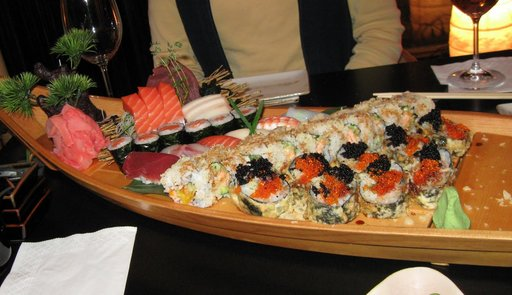

In [9]:
# 4. Open image
img = Image.open(random_image_path)

# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img

(np.float64(-0.5), np.float64(511.5), np.float64(294.5), np.float64(-0.5))

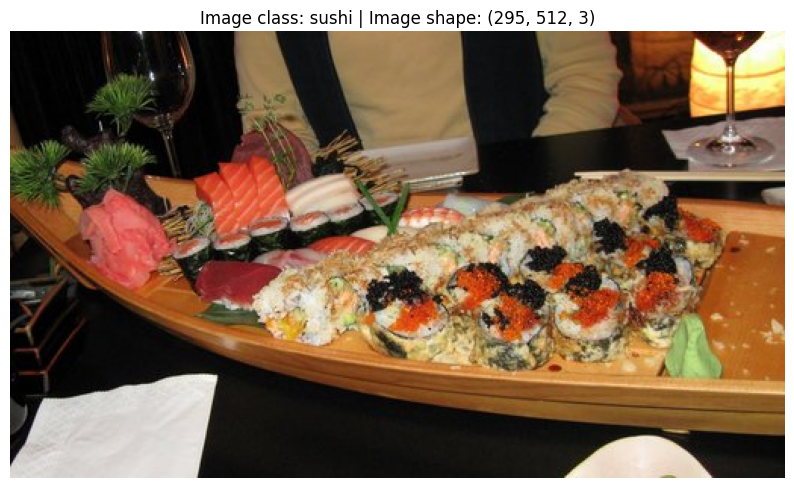

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Turn the image into an array
img_as_array = np.asarray(img)

# Plot the image wirh matplotplib
plt.figure(figsize=(10, 7))
plt.imshow(img_as_array)
plt.title(f"Image class: {image_class} | Image shape: {img_as_array.shape}")
plt.axis(False)

## 3. Transforming data

Before we can user our image data (audio, text, rec and rest) with PyTorch:
1. Turn your target data into tensors (in our case, numerical representaion of our images.)
2. Turn it into a `torch.utils.data.Dataset` and subsequently a `torch.utils.data.DataLoader`, we'll call this DataSet and DataLoader

In [11]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

### 3.1 Transforming data with `torchvision.transforms`

In [12]:
# Write a transform for image
data_transform = transforms.Compose([ # To combine transforms
    # Resize our images for 64x64
    transforms.Resize(size=(64, 64)),
    # Flip the image randomly on the horizontal
    transforms.RandomHorizontalFlip(p=0.5),
    # Turn the image into a torch tensor
    transforms.ToTensor()
])

In [13]:
data_transform(img).shape

torch.Size([3, 64, 64])

In [14]:
def plot_transformed_images(image_paths, transform, n=3, seed=None):
  """
  Selects random images from a path of images and loads/tranforms thema nd then plots the ooriginal vs the tranfsormed version.
  """

  if seed:
    random.seed(seed)

  random_image_paths = random.sample(image_paths, k=n)

  for image_path in random_image_paths:
    with Image.open(image_path) as f:
      fig, ax = plt.subplots(1, 2)
      ax[0].imshow(f)
      ax[0].set_title(f"Original\nSize: {f.size}")
      ax[0].axis(False)

      # Transform and plot target image
      transformed_image = transform(f).permute(1, 2, 0) # Note we will need to change shape for matplotlib
      ax[1].imshow(transformed_image)
      ax[1].set_title(f"Transformed\nShape: {transformed_image.shape}")
      ax[1].axis(False)

      fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

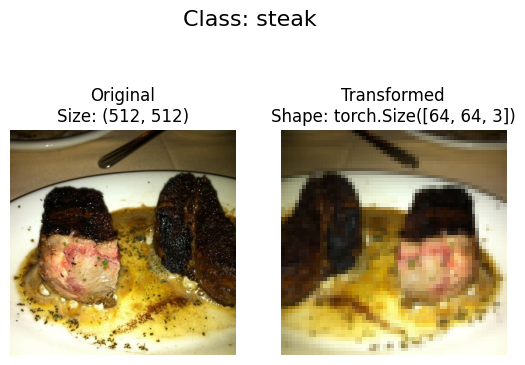

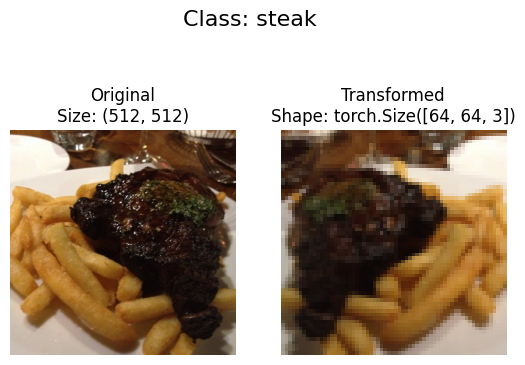

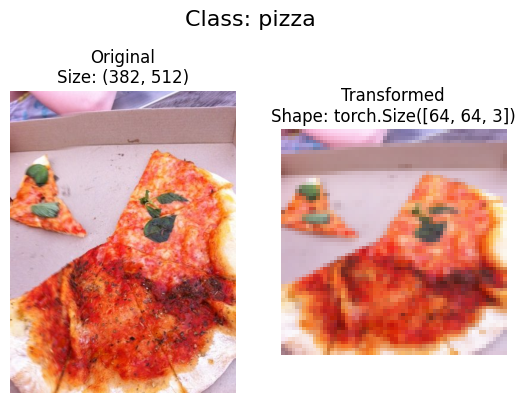

In [15]:
plot_transformed_images(image_path_list,
                        data_transform,
                        n=3,
                        seed=42)

## 4. Option 1: Loading image data using ImageFolder

We can load image classification data using `toerchvision.datasets.ImageFolder`

In [16]:
# Use ImageFolder to create Dataset(s)
from torchvision import datasets
train_data = datasets.ImageFolder(root=train_dir,
                                  transform=data_transform,
                                  target_transform=None)

test_data = datasets.ImageFolder(root=test_dir,
                                 transform=data_transform,
                                 target_transform=None)

train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [17]:
 # Get class mnames as a list
class_names = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [18]:
# Get class names as dict
class_dict = train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [19]:
# Check the lengths of our dataset
len(train_data), len(test_data)

(225, 75)

In [20]:
# Index on train_data Dataset to get a single image and label
img, label = train_data[0]
print(f"Image tensor:\n {img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image tensor:
 tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
         [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
         [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
         ...,
         [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
         [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
         [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],

        [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
         [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
         [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
         ...,
         [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
         [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
         [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],

        [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
         [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
         [0.0196, 0.0157, 0.0157,  ..., 0.0

In [21]:
class_names[label]

'pizza'

Original shape: torch.Size([3, 64, 64]) -> [color_channels, height, width]
Image permute: torch.Size([64, 64, 3]) -> [height, width, color_channels]


Text(0.5, 1.0, 'pizza')

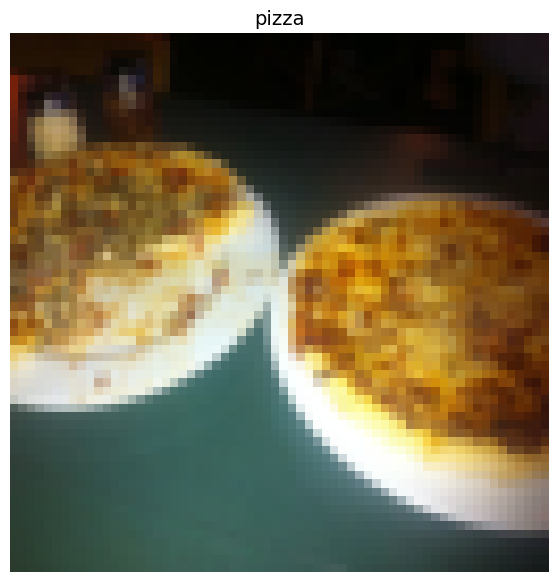

In [22]:
# Rearrange the order dimensions
img_permute = img.permute(1, 2, 0)

# Print out different shapes
print(f"Original shape: {img.shape} -> [color_channels, height, width]")
print(f"Image permute: {img_permute.shape} -> [height, width, color_channels]")

# Plot the image
plt.figure(figsize=(10, 7))
plt.imshow(img_permute)
plt.axis(False)
plt.title(class_names[label], fontsize=14)


In [23]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(dataset=train_data,
                              batch_size=1,
                              num_workers=1, # os.cpu_count()
                              shuffle=True)

test_dataloader = DataLoader(dataset=test_data,
                             batch_size=1,
                             num_workers=1,
                             shuffle=False)

In [24]:
train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7fad45c937a0>,
 <torch.utils.data.dataloader.DataLoader at 0x7fad45cb44a0>)

In [25]:
len(train_dataloader), len(test_dataloader)

(225, 75)

In [26]:
img, label = next(iter(train_dataloader))

# Batch size will now be 1
print(f"Image shape: {img.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label.shape}")

Image shape: torch.Size([1, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([1])


## 5. Option 2: Loading image data with a custom `Dataset`

1. Want to be able to load images from file
2. Want to be able to get class anmes from the Datasset
3. Want to be able to get classes as dictionary from the dataset

Pros:
* Can create a `Dataset` out of almost anything
* Not limited to PyTorch pre-built `Dataset` fucntions

Cons:
* Even though you could create `Dataset` out of almost anything, it doesn't mean it will work...
* Using a custom `Dataset` often results in us writing more could, which could be prone to errors or perfromance issues.


All custom datasets in PyTorch, often subclass class Dataset.

In [27]:
import os
import pathlib
import torch

from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from typing import Tuple, Dict, List

In [28]:
# Instance of torchvision.datasets.ImageFolder()
train_data.classes, train_data.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

### 5.1 Creaing a helper function to get class names

We want a function to:
1. Get the class names using `os.scandir()` to traverse a target directory (ideally the directory is in standard image classification format)
2. Raise an error if the class names aren't found (if this happens, there mightbe sometihgnw rong with the directory structure.)
3. Turn the class names into a dict and a list and return them.

In [29]:
# Setup path for target directory
target_directory = train_dir
print(f"Target dir: {target_directory}")

# Get the class names fro the target directory
class_names_found = sorted([entry.name for entry in list(os.scandir(target_directory))])
class_names_found

Target dir: data/pizza_steak_sushi/train


['pizza', 'steak', 'sushi']

In [30]:
def find_classes(directory: str) -> Tuple[List[str], Dict[str, int]]:
  """
  Finds the class folder names in a target directory.
  """

  # 1. Get the class names by scanning the target directory
  classes = sorted(entry.name for entry in list(os.scandir(target_directory)) if entry.is_dir())

  # 2. Raise an error if class names could not be found
  if not classes:
    raise FileNotFoundError(f"Couldn't find any classes in {directory}...please check file structure")

  # 3. Create dictionary of index labels
  class_to_idx = {class_name: i for i, class_name in enumerate(classes)}

  return classes, class_to_idx

In [31]:
find_classes(target_directory)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

### 5.2 Create a custom `Dataset` to replicate `ImageFolder`

To create our own custom dataset, we want to:

1. Subclass `torch.utils.data.DataSet`
2. Init out subclass with a target directory (the directory we'd like to get data from ) as well as a transfrom if we`d like to transform our data.
3. Create several attributes:
  * paths - paths of our images
  * transfrom - the transform we'd like to use
  * classes - a list of target classes
  * class_to_idx - a dict of the target classes mappend to integer labels
4. Create a functino to `load_images()`
5. Override the `__len__()` to return the length of our dataset
6. Overwrute the `__getitem()__` to return a given sample when passed an index

In [32]:
# 0. Write a custom dataset class
from torch.utils.data import Dataset

# 1. Subclass torch.utils.data.Dataset

class ImageFolderCustom(Dataset):
  # 2. Initialize our custom dataset
  def __init__(self, targ_dir: str, transform = None):
    # 3. Create class atributes

    # Get all of the image paths
    self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg"))
    # Setup transforms
    self.transform = transform
    # Create classes and class_to_idx attributes
    self.classes, self.class_to_idx = find_classes(targ_dir)

  # 4. Create function to load images
  def load_image(self, index: int) -> Image.Image:
    "Opens an image via a path and returns it."
    image_path = self.paths[index]
    return Image.open(image_path)

  # 5. Overwrite __len__()
  def __len__(self) -> int:
    "Returns the total amount of samples."
    return len(self.paths)

  # 6. Overwrite __getitem__() to return a praticular sample
  def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
    "Returns one sample of data, data and label (X, y)."

    img = self.load_image(index)
    class_name = self.paths[index].parent.stem # expects path in formaat: data_folder/class_name/name.jpg
    class_idx = self.class_to_idx[class_name]

    # Transform if neccesary
    if self.transform:
      return self.transform(img), class_idx # return data, label (X, y)
    else:
      return img, class_idx


In [33]:
# Create a transform
train_transform = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.ToTensor()
])

In [34]:
# Test out ImageFolderCustom
train_data_custom = ImageFolderCustom(targ_dir=train_dir,
                                      transform=train_transform)

test_data_custom = ImageFolderCustom(targ_dir=test_dir,
                                     transform=test_transform)

In [35]:
train_data_custom, test_data_custom

(<__main__.ImageFolderCustom at 0x7fad45bb1e80>,
 <__main__.ImageFolderCustom at 0x7fad45b333e0>)

In [36]:
len(train_data), len(train_data_custom)

(225, 225)

In [37]:
len(test_data), len(test_data_custom)

(75, 75)

In [38]:
train_data_custom.classes

['pizza', 'steak', 'sushi']

In [39]:
train_data_custom.class_to_idx

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [40]:
# Check for equality between original ImageFolder and ImageFolderCustom
print(train_data_custom.classes == train_data.classes)
print(test_data_custom.classes == test_data.classes)

True
True


### 5.3 Create a function to display random images

1. Take in a `Dataset` and a number of other parameters such as class name sand how manuy images to visualize.
2. To prevent the display getting out of hand, let's cap the number of images to see at 10.
3. Set the random seed for reproducibility
4. Get a list of random sample imdexes from the target dataset.
5. Setup matplotlib plot.
6. Loop through the random smaple indexes and plot them with matplotlib.
7. Make sure the dimensions of our image sline with matplotlib (HWC)

In [41]:
# 1. Create a function to take in a daetaset
def display_random_images(dataset: torch.utils.data.Dataset,
                          classes: List[str]=None,
                          n: int=10,
                          display_shape: bool=True,
                          seed: int=None):

  # 2. Adjust the display if n is too high
  if n > 10:
    n = 10
    display_shape = False
    print(f"For display purposes, n should'nt be larget thatn 10.")

  # 3. Set the seed
  if seed:
    random.seed(seed)

  # 4. Get random sample indexes
  random_sample_idx = random.sample(range(len(dataset)), k=n)

  # 5. Setup plot
  plt.figure(figsize=(16, 8))

  # 6. Loop through random indexes annd plot the with matplotlib
  for i, targ_sample in enumerate(random_sample_idx):
    targ_image, targ_label = dataset[targ_sample]

    # 7. Adjust tensor dimensions for plotting
    targ_image_adjust = targ_image.permute(1, 2, 0) # [HWC]

    # Plot adjusted samples
    plt.subplot(1, n, i+1)
    plt.imshow(targ_image_adjust)
    plt.axis(False)
    if classes:
      title = f"Class: {classes[targ_label]}"
      if display_shape:
        title = title + f"\nShape: {targ_image_adjust.shape}"

    plt.title(title)

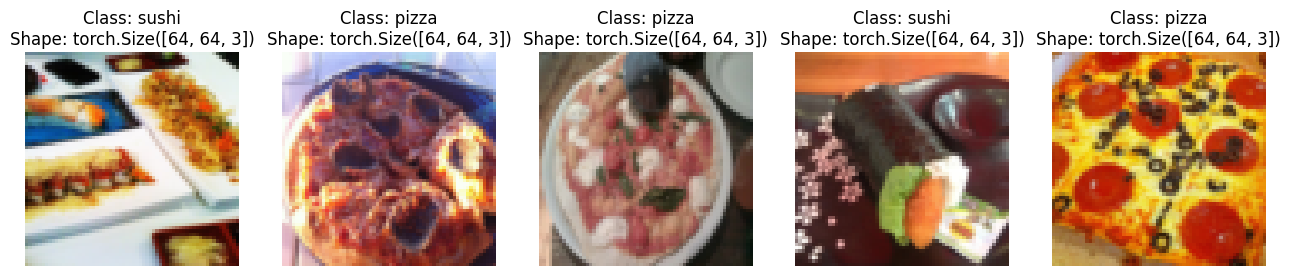

In [42]:
# Display random images from ImageFolder created Dataset
display_random_images(train_data,
                      n=5,
                      classes=class_names,
                      seed=42)

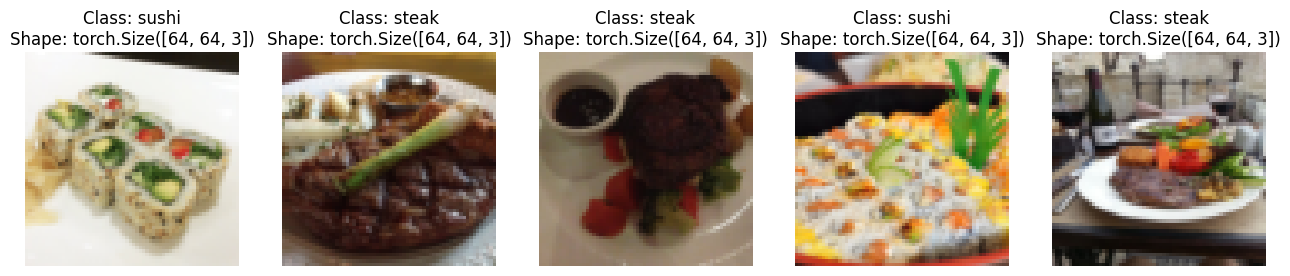

In [43]:
# Dsiplay rnadom images from ImgeFolderCustom Dataset
display_random_images(train_data_custom,
                      n=5,
                      classes=class_names,
                      seed=42)

### 5.4 Turn custom loaded images into `DataLoader`'s

In [44]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_dataloader_custom = DataLoader(dataset=train_data_custom,
                                     batch_size=BATCH_SIZE,
                                     num_workers=0,
                                     shuffle=True)

test_dataloader_custom = DataLoader(dataset=test_data_custom,
                                    batch_size=BATCH_SIZE,
                                    num_workers=0,
                                    shuffle=False)

In [45]:
# Get image and label from custom dataloader
img_custom, label_custom = next(iter(train_dataloader_custom))
img_custom.shape, label_custom.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

## 6. Other forms of transforms (data augmentation)

Data augmentaions is the process of artificaly adding diversity to you training data,

Int ehc ase of image data, this may mean applyting variuous image transformasions.

Let's take a look at one particular type of data augmentaiton used to train PyTorch vision models to state of the art levels..

In [46]:
# Let's look at trivial augment
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize(size=(224, 224)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor()

])

test_transform = transforms.Compose([
    transforms.Resize(size=(224, 224)),
    transforms.ToTensor()
])

In [47]:
# Get all image paths
image_path_list = list(image_path.glob("*/*/*.jpg"))

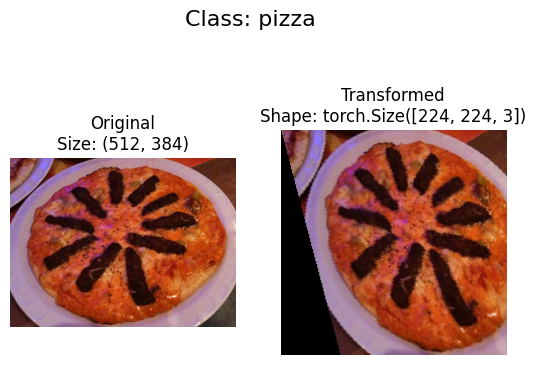

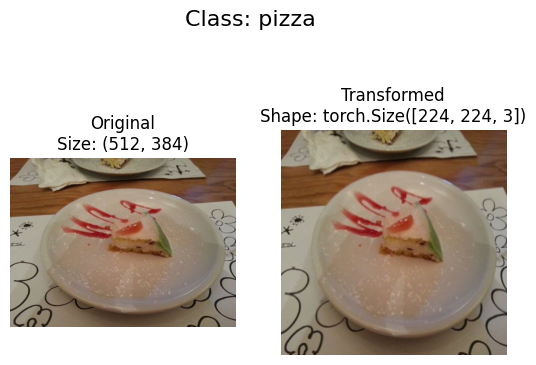

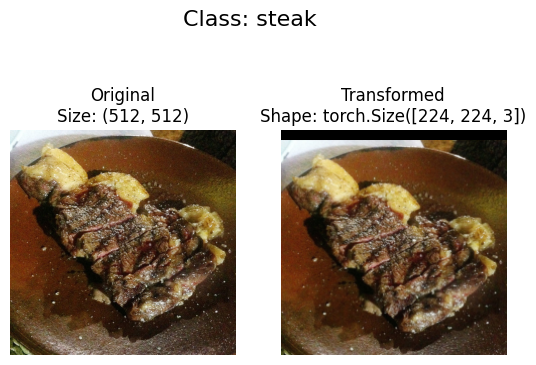

In [48]:
# Plot random transformed images
plot_transformed_images(
    image_paths=image_path_list,
    transform=train_transform,
    n=3,
    seed=None
)

## 7. Model 0: TinyVGG architecture without data augmentation

## 7.1 Creating transorms and loading data for Model 0

In [49]:
# Creatae simple transfrom
simple_transform = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.ToTensor()
])

In [50]:
# 1. Load and transform data
from torchvision import datasets
train_data_simple = datasets.ImageFolder(root=train_dir,
                                         transform=simple_transform,
                                         target_transform=None)

test_data_simple = datasets.ImageFolder(root=test_dir,
                                        transform=simple_transform,
                                        target_transform=None)

# 2. Turn the datasets into dataloaders
import os
from torch.utils.data import DataLoader

# Setup batch size and number of workers
BATCH_SIZE=32
NUM_WORKERS = os.cpu_count()

# Create dataloaders
train_dataloader_simple = DataLoader(dataset=train_data_simple,
                                     batch_size=BATCH_SIZE,
                                     num_workers=NUM_WORKERS,
                                     shuffle=True)

test_dataloader_simple = DataLoader(dataset=test_data_simple,
                                    batch_size=BATCH_SIZE,
                                    num_workers=NUM_WORKERS,
                                    shuffle=False)

In [51]:
import torch
from torch import nn

class TinyVGG(nn.Module):
  def __init__(self,
               input_shape: int,
               hidden_units: int,
               output_shape: int):

    super().__init__()

    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=0),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=0),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2) # default stride value is same as kernel_size
    )

    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=0),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=0),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,
                     stride=2)
    )

    self.classifier_layer = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*13*13,
                  out_features=output_shape)
    )

  def forward(self, x):
    x = self.conv_block_1(x)
    #print(x.shape)
    x = self.conv_block_2(x)
    #print(x.shape)
    x = self.classifier_layer(x)
    #print(x.shape)
    return x


In [52]:
torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(class_names)).to(device)

next(model_0.parameters()).device

device(type='cuda', index=0)

In [53]:
image_batch, label_batch = next(iter(train_dataloader_simple))
image_batch.shape, label_batch.shape


(torch.Size([32, 3, 64, 64]), torch.Size([32]))

In [54]:

model_0(image_batch.to(device))

tensor([[ 2.0795e-02, -1.9510e-03,  9.5212e-03],
        [ 1.8440e-02,  2.4669e-03,  6.6609e-03],
        [ 1.7695e-02,  1.0282e-03,  9.4975e-03],
        [ 2.4446e-02, -3.3489e-03,  9.5877e-03],
        [ 1.9939e-02,  6.9129e-04,  1.0778e-02],
        [ 2.1281e-02,  2.0434e-03,  5.0046e-03],
        [ 2.0996e-02,  1.6417e-04,  1.2481e-02],
        [ 2.1566e-02, -1.9607e-03,  9.7175e-03],
        [ 2.4500e-02, -4.7904e-03,  8.5394e-03],
        [ 2.0239e-02, -4.7980e-04,  1.0907e-02],
        [ 2.2219e-02, -4.1815e-04,  9.8173e-03],
        [ 2.2318e-02, -2.1642e-03,  9.4428e-03],
        [ 2.1851e-02, -3.7225e-03,  8.3784e-03],
        [ 2.2881e-02, -1.7559e-03,  1.0299e-02],
        [ 2.1635e-02, -4.3994e-03,  9.4990e-03],
        [ 2.2101e-02, -4.1469e-03,  9.3904e-03],
        [ 2.1226e-02, -4.4215e-03,  1.1476e-02],
        [ 2.1698e-02, -2.7458e-03,  8.4966e-03],
        [ 1.9974e-02, -3.2317e-07,  8.4496e-03],
        [ 1.8308e-02,  1.6378e-03,  8.5491e-03],
        [ 2.0768e-02

In [55]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.1)

In [56]:
!pip install -q torchinfo

### Use `torchinfo` to get an idea of the shapes through the model

In [57]:
import torchinfo
from torchinfo import summary
summary(model_0, input_size=[1, 3, 64, 64])

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 10, 30, 30]           --
│    └─Conv2d: 2-1                       [1, 10, 62, 62]           280
│    └─ReLU: 2-2                         [1, 10, 62, 62]           --
│    └─Conv2d: 2-3                       [1, 10, 60, 60]           910
│    └─ReLU: 2-4                         [1, 10, 60, 60]           --
│    └─MaxPool2d: 2-5                    [1, 10, 30, 30]           --
├─Sequential: 1-2                        [1, 10, 13, 13]           --
│    └─Conv2d: 2-6                       [1, 10, 28, 28]           910
│    └─ReLU: 2-7                         [1, 10, 28, 28]           --
│    └─Conv2d: 2-8                       [1, 10, 26, 26]           910
│    └─ReLU: 2-9                         [1, 10, 26, 26]           --
│    └─MaxPool2d: 2-10                   [1, 10, 13, 13]           --
├─Sequentia

In [58]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")):

    model.train()
    model.to(device)

    train_loss, correct_preds, total_preds = 0.0, 0, 0

    for X, y in dataloader:
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate the loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        # 3. Predictions
        y_pred_lab = y_pred.argmax(dim=1)
        correct_preds += (y_pred_lab == y).sum().item()
        total_preds += y.size(0)

        # 4. Optimizer step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Average loss across batches
    train_loss /= len(dataloader)
    # Accuracy as percentage
    train_acc = (correct_preds / total_preds) * 100

    return train_loss, train_acc


In [59]:
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")):

    model.to(device)
    model.eval()
    test_loss, correct_preds, total_preds = 0.0, 0, 0

    with torch.inference_mode():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            # 1. Forward pass
            y_pred = model(X)

            # 2. Calculate loss
            loss = loss_fn(y_pred, y)
            test_loss += loss.item()

            # 3. Predictions and accuracy
            y_labels = y_pred.argmax(dim=1)
            correct_preds += (y_labels == y).sum().item()
            total_preds += y.size(0)

    # Average loss across batches
    test_loss /= len(dataloader)
    # Accuracy as percentage
    test_acc = (correct_preds / total_preds) * 100

    return test_loss, test_acc


In [60]:
from timeit import default_timer as timer
from tqdm.auto import tqdm

def train_test_loop(model: torch.nn.Module,
                    loss_fn: torch.nn.Module,
                    optimizer: torch.optim.Optimizer,
                    train_dataloader: torch.utils.data.DataLoader,
                    test_dataloader: torch.utils.data.DataLoader,
                    seed: int = None,
                    device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu"),
                    epochs: int = 3):

    # Set seeds for reproducibility
    if seed:
        torch.manual_seed(seed)
        torch.cuda.manual_seed(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []}

    start_time = timer()

    for epoch in tqdm(range(epochs)):
        print(f"\nEpoch {epoch+1}/{epochs}\n--------------------------")

        # Training step
        train_loss, train_acc = train_step(model,
                                           train_dataloader,
                                           loss_fn,
                                           optimizer,
                                           device)

        # Testing step
        test_loss, test_acc = test_step(model,
                                        test_dataloader,
                                        loss_fn,
                                        device)

        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Test Loss:  {test_loss:.4f} | Test Acc:  {test_acc:.2f}%")

        # Store results
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

    end_time = timer()
    runtime = end_time - start_time

    print(f"\nRuntime on {device}: {runtime:.3f} seconds")
    return results


In [61]:
model_0 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(class_names)).to(device)

In [62]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(),
                            lr=0.001)

In [63]:
model_0_results = train_test_loop(model_0,
                loss_fn,
                optimizer,
                train_dataloader,
                test_dataloader,
                seed=42,
                device=device,
                epochs=5)

  0%|          | 0/5 [00:00<?, ?it/s]


Epoch 1/5
--------------------------
Train Loss: 1.1041 | Train Acc: 35.56%
Test Loss:  1.0936 | Test Acc:  40.00%

Epoch 2/5
--------------------------
Train Loss: 1.0614 | Train Acc: 43.11%
Test Loss:  1.2796 | Test Acc:  38.67%

Epoch 3/5
--------------------------
Train Loss: 0.9863 | Train Acc: 47.56%
Test Loss:  0.9834 | Test Acc:  41.33%

Epoch 4/5
--------------------------
Train Loss: 0.9231 | Train Acc: 55.11%
Test Loss:  1.0037 | Test Acc:  44.00%

Epoch 5/5
--------------------------
Train Loss: 0.9056 | Train Acc: 57.78%
Test Loss:  0.9741 | Test Acc:  46.67%

Runtime on cuda: 7.558 seconds


### 7.8 Plot the loss curves of Model 0

A **loss curve** is a way of trakcing your models progress over time.

In [64]:
# Get the model_0_results keys
model_0_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

In [65]:
def plot_loss_curves(results: Dict[str, List[float]]):
  """
  Plots training curves of a results dictionary.
  """

  # Get the loss values of the results dictionary (training and test)
  loss = results["train_loss"]
  test_loss = results["test_loss"]

  # Get the accuracy values of the results dictinoary (train and test)
  acc = results["train_acc"]
  test_acc = results["test_acc"]

  # Figure out how many epochs there were
  epochs = range(len(results["train_loss"]))

  # Setup a plot
  plt.figure(figsize=(15, 7))

  # Plot the loss
  plt.subplot(1, 2, 1)
  plt.plot(epochs, loss, label="train_loss")
  plt.plot(epochs, test_loss, label="test_loss")
  plt.title("Loss")
  plt.xlabel("Epochs")
  plt.legend()

  # Plot the accuracy
  plt.subplot(1, 2, 2)
  plt.plot(epochs, acc, label="train_accuracy")
  plt.plot(epochs, test_acc, label="test_acc")
  plt.title("Accuracy")
  plt.xlabel("Epochs")
  plt.legend()

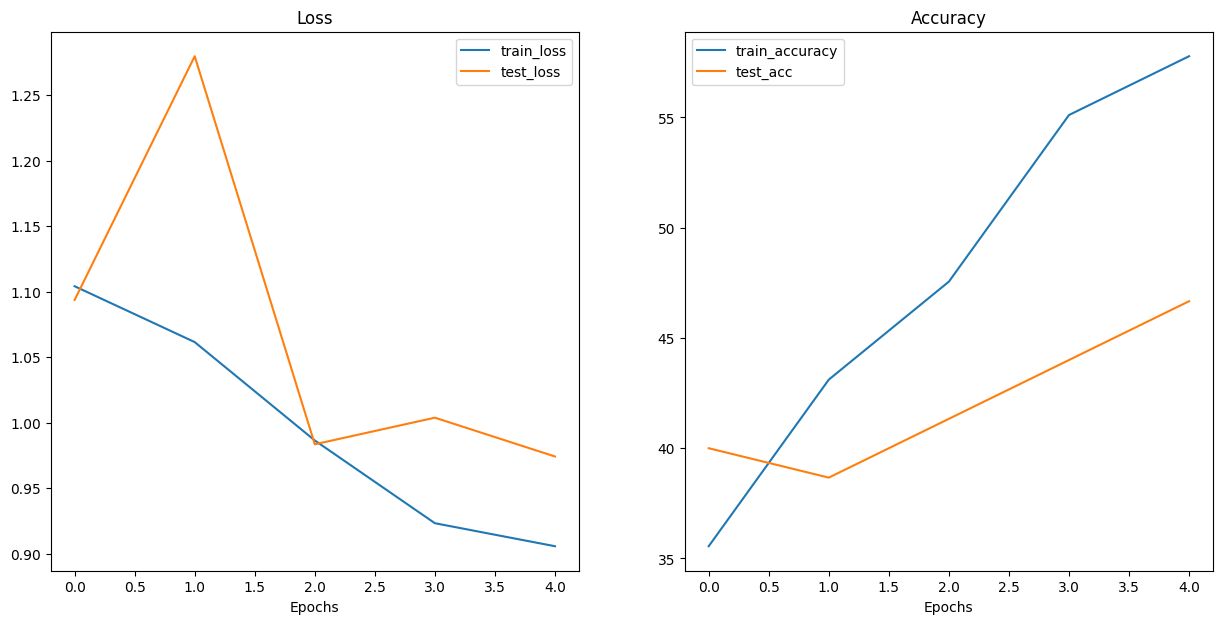

In [66]:
plot_loss_curves(model_0_results)

## 8. What should an ideal loss curve look like?

https://developers.google.com/machine-learning/crash-course/overfitting/interpreting-loss-curves


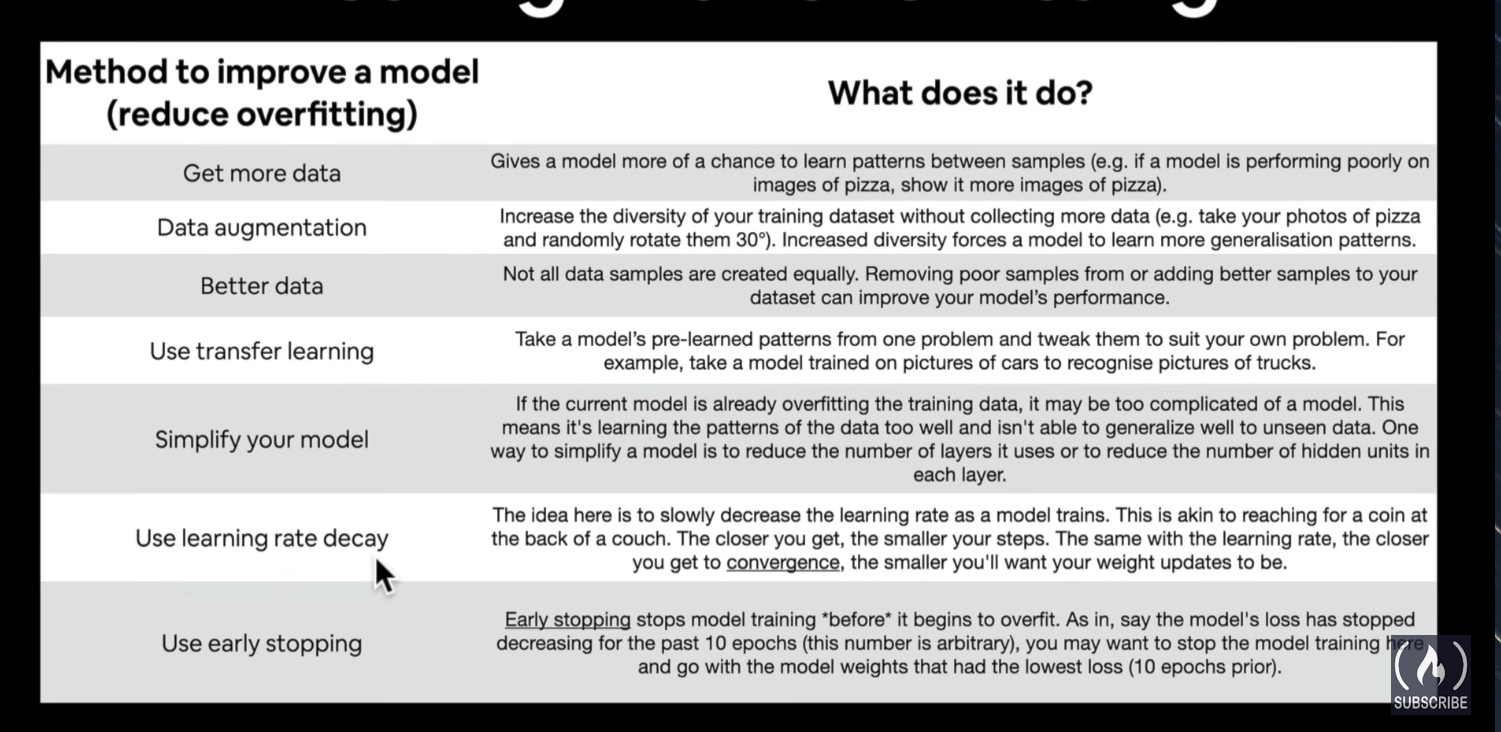

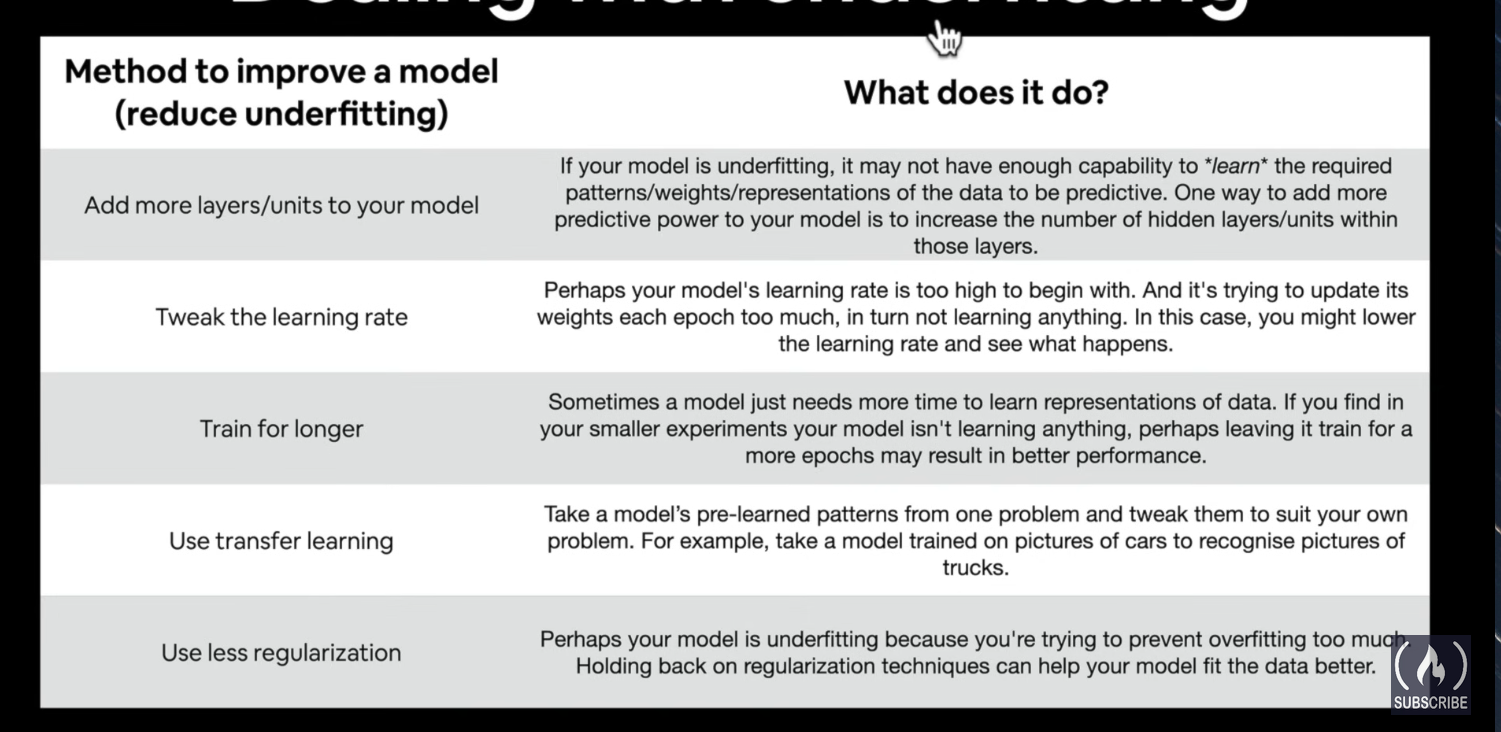

## 9. Model 1: Tiny VGG with Data Augmentation

Now let's try another modlling experminet this time using the same model as before with some data augmentaiton

### 9.1 Create transfrom with data augmetnaiton

In [67]:
# Create training transfrom wtih TrivialAugmnet
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

train_transform_trivial = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor()
])

test_transform_trivial = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.ToTensor()
])

### 9.2 Create train and test datasets and DataLoaders with dataugmentaiton

In [68]:
train_data_augment = datasets.ImageFolder(root=train_dir,
                                          transform=train_transform_trivial,
                                          target_transform=None)

test_data_simple = datasets.ImageFolder(root=test_dir,
                                         transform=test_transform_trivial,
                                         target_transform=None)

train_dataloader_augment = DataLoader(dataset=train_data_augment,
                                      batch_size=32,
                                      num_workers = os.cpu_count(),
                                      shuffle=True)

test_dataloader_simple = DataLoader(dataset=test_data_simple,
                                     batch_size=32,
                                     num_workers=os.cpu_count(),
                                     shuffle=False)

In [69]:
model_1 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(class_names)).to(device)

In [70]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_1.parameters(),
                             lr = 0.001)

In [71]:
model_1_results = train_test_loop(model_1,
                                  loss_fn,
                                  optimizer,
                                  train_dataloader_augment,
                                  test_dataloader_simple,
                                  seed=42,
                                  device=device,
                                  epochs=5)

  0%|          | 0/5 [00:00<?, ?it/s]


Epoch 1/5
--------------------------
Train Loss: 1.1058 | Train Acc: 32.00%
Test Loss:  1.0925 | Test Acc:  41.33%

Epoch 2/5
--------------------------
Train Loss: 1.0895 | Train Acc: 34.67%
Test Loss:  1.1098 | Test Acc:  33.33%

Epoch 3/5
--------------------------
Train Loss: 1.0785 | Train Acc: 34.67%
Test Loss:  1.1370 | Test Acc:  33.33%

Epoch 4/5
--------------------------
Train Loss: 1.1181 | Train Acc: 34.67%
Test Loss:  1.1511 | Test Acc:  33.33%

Epoch 5/5
--------------------------
Train Loss: 1.0830 | Train Acc: 34.67%
Test Loss:  1.1424 | Test Acc:  33.33%

Runtime on cuda: 6.050 seconds


In [72]:
model_0_results

{'train_loss': [1.1040613304244147,
  1.0614131218857235,
  0.9863223487221532,
  0.9231438320802732,
  0.9055832452740934],
 'train_acc': [35.55555555555556,
  43.111111111111114,
  47.55555555555556,
  55.111111111111114,
  57.77777777777777],
 'test_loss': [1.0935651429494222,
  1.2796434881786505,
  0.983398058116436,
  1.0037048863371214,
  0.9740825971961021],
 'test_acc': [40.0,
  38.666666666666664,
  41.333333333333336,
  44.0,
  46.666666666666664]}

In [73]:
model_1_results

{'train_loss': [1.1058220565319061,
  1.08946393430233,
  1.0785211622714996,
  1.1181135475635529,
  1.0830473452806473],
 'train_acc': [32.0,
  34.66666666666667,
  34.66666666666667,
  34.66666666666667,
  34.66666666666667],
 'test_loss': [1.0924752950668335,
  1.1098057826360066,
  1.1369974811871846,
  1.1511375109354656,
  1.1424342393875122],
 'test_acc': [41.333333333333336,
  33.33333333333333,
  33.33333333333333,
  33.33333333333333,
  33.33333333333333]}

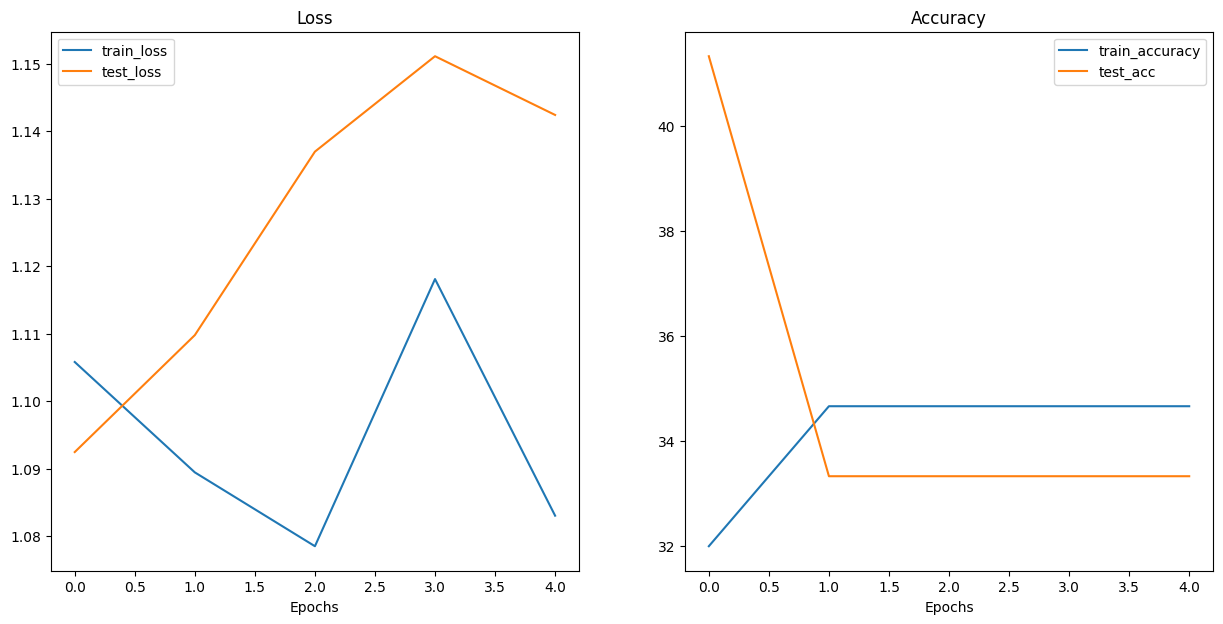

In [74]:
plot_loss_curves(model_1_results)

## 10. Compare model results

After evaluating our modelling experiments on their worn, it's important to compare them to each othewr.

There's a fre different ways to do this:
1. Hard coding (like we're doing)
2. PyTorch + TensorBoard
3. Weights & Biases
4. MLFlow

In [75]:
import pandas as pd
model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)
model_0_df

,train_loss,train_acc,test_loss,test_acc
0,1.104061,35.555556,1.093565,40.000000
1,1.061413,43.111111,1.279643,38.666667
2,0.986322,47.555556,0.983398,41.333333
3,0.923144,55.111111,1.003705,44.000000
4,0.905583,57.777778,0.974083,46.666667


In [76]:
model_1_df

,train_loss,train_acc,test_loss,test_acc
0,1.105822,32.000000,1.092475,41.333333
1,1.089464,34.666667,1.109806,33.333333
2,1.078521,34.666667,1.136997,33.333333
3,1.118114,34.666667,1.151138,33.333333
4,1.083047,34.666667,1.142434,33.333333


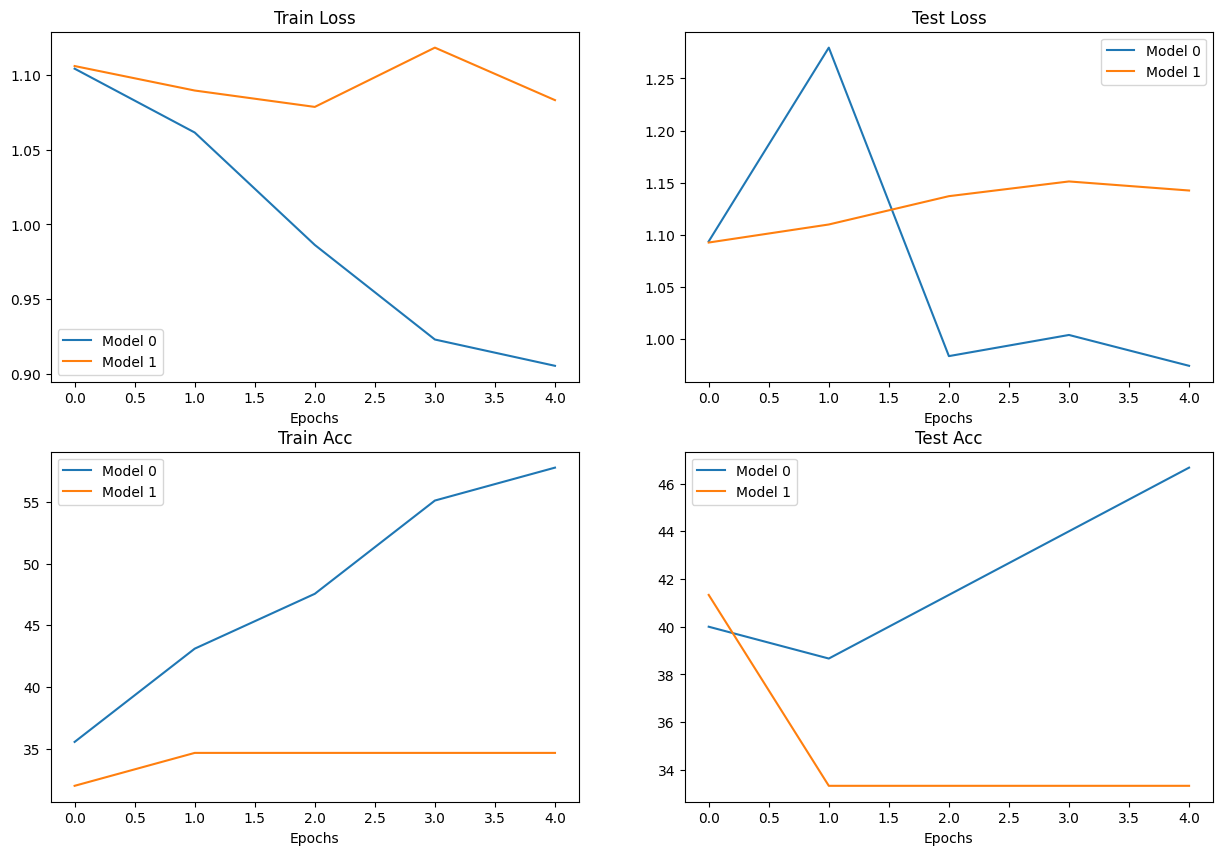

In [77]:
# Setup a plot
plt.figure(figsize=(15, 10))

# Get number of epochs
epochs = range(len(model_0_df))

# Plot train loss
plt.subplot(2, 2, 1)
plt.plot(epochs, model_0_df["train_loss"], label="Model 0")
plt.plot(epochs, model_1_df["train_loss"], label="Model 1")
plt.title("Train Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot test loss
plt.subplot(2, 2, 2)
plt.plot(epochs, model_0_df["test_loss"], label="Model 0")
plt.plot(epochs, model_1_df["test_loss"], label="Model 1")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot train acc
plt.subplot(2, 2, 3)
plt.plot(epochs, model_0_df["train_acc"], label="Model 0")
plt.plot(epochs, model_1_df["train_acc"], label="Model 1")
plt.title("Train Acc")
plt.xlabel("Epochs")
plt.legend()

# Plot test acc
plt.subplot(2, 2, 4)
plt.plot(epochs, model_0_df["test_acc"], label="Model 0")
plt.plot(epochs, model_1_df["test_acc"], label="Model 1")
plt.title("Test Acc")
plt.xlabel("Epochs")
plt.legend()

## 11. Making a prediction on a custom image

Alhough we've trainded a model on custom data... how do you make a prediction on a sample/image that's not in either trianing or testing dataset.

In [112]:
# Donwload custom image
import requests

# Setup custom image path
custom_image_path = pathlib.Path("/content/data/a.jpeg")

# Download the image if it does not alreay exist
if not custom_image_path.is_file():
  with open(custom_image_path, "wb") as f:
    request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpg")
    print(f"Donwloading {custom_image_path}")
    f.write(request.content)
else:
  print(f"{custom_image_path} alerady exist...skiiping download")

/content/data/a.jpeg alerady exist...skiiping download


### 11.1 Loading in a custom image with PyTorch

We have to make sure our custom image is in the same fromat as the data our model was trained on.

* in tnsor form with dataype (torch.float32)
* Of shape 64x64
* On the right device

In [81]:
import torchvision

# Read in custom mage
custom_image_uint8 = torchvision.io.read_image(str(custom_image_path))
print(f"Custom image tensor:\n {custom_image_uint8}")
print(f"Custom image shape: {custom_image_uint8.shape}")
print(f"Custom image datatype: {custom_image_uint8.dtype}")

Custom image tensor:
 tensor([[[  0,   0,   0,  ...,  91,  41,  37],
         [  0,   0,   0,  ...,  62,  49,  20],
         [  0,   1,   3,  ...,  33,  50,   3],
         ...,
         [  9,   6,   2,  ...,   8,   8,   8],
         [  7,   3,   1,  ...,   8,   8,   8],
         [  4,   1,   1,  ...,   8,   8,   8]],

        [[  6,   6,   6,  ..., 102,  51,  47],
         [  5,   5,   5,  ...,  73,  59,  30],
         [  4,   3,   4,  ...,  42,  58,  11],
         ...,
         [  8,   5,   0,  ...,   9,   9,   9],
         [  6,   1,   0,  ...,   9,   9,   9],
         [  2,   0,   0,  ...,   9,   9,   9]],

        [[  0,   0,   0,  ..., 108,  53,  49],
         [  0,   0,   0,  ...,  79,  61,  32],
         [  0,   0,   0,  ...,  49,  61,  14],
         ...,
         [  3,   1,   3,  ...,  11,  11,  11],
         [  4,   2,   2,  ...,  11,  11,  11],
         [  3,   2,   4,  ...,  11,  11,  11]]], dtype=torch.uint8)
Custom image shape: torch.Size([3, 183, 275])
Custom image dataty

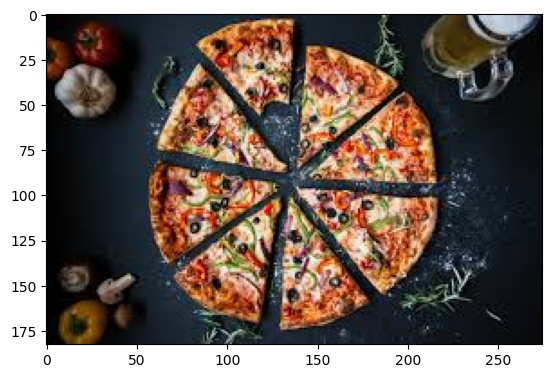

In [82]:
plt.imshow(custom_image_uint8.permute(1, 2, 0))

## 11.2 Making a predicting on a custom image with a PyTorch model

In [83]:
custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32) / 255.

In [84]:
# Create transofrm pipeline to reszie image
from torchvision import transforms
custom_image_transform = transforms.Compose([
    transforms.Resize(size=(64, 64))
])

# Transfrom traget image
custom_image_transformed = custom_image_transform(custom_image)

# Print out the shape
print(f"Original shape: {custom_image.shape}")
print(f"Transformed shape: {custom_image_transformed.shape}")

Original shape: torch.Size([3, 183, 275])
Transformed shape: torch.Size([3, 64, 64])


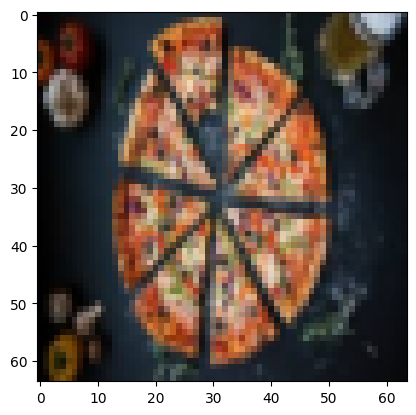

In [85]:
plt.imshow(custom_image_transformed.permute(1, 2, 0))

In [86]:
# Trh to make a prediction on a image in uint8 fomrat
model_1.eval()
with torch.inference_mode():
  model_1(custom_image_transformed.to(device))

RuntimeError: mat1 and mat2 shapes cannot be multiplied (10x169 and 1690x3)

In [87]:
custom_image_transformed=custom_image_transformed.unsqueeze(0)

In [88]:
# Trh to make a prediction on a image in uint8 fomrat
model_1.eval()
with torch.inference_mode():
  custom_image_pred = model_1(custom_image_transformed.to(device))

custom_image_pred

tensor([[ 0.0910, -0.0347, -0.1556]], device='cuda:0')

Note, to make a prediction on a custom image we had to:
* Load the image and turn it into a tensor
* Make sure the imaghe was the same datatype as the model
* Make sure the image was the same shape as the data the model was trained on (3, 64, 64) with a batch size... (1, 3, 64, 64)
* Make sure the image is on the same device as the model

In [89]:
# Convert logits to pred prob
custom_image_pred_probs = torch.softmax(custom_image_pred, dim=1)
custom_image_pred_probs

tensor([[0.3755, 0.3311, 0.2934]], device='cuda:0')

In [91]:
# Convert pred prob to pred labels
custom_image_pred_label = torch.argmax(custom_image_pred_probs, dim=1)
custom_image_pred_label

tensor([0], device='cuda:0')

In [92]:
class_names[custom_image_pred_label]

'pizza'

### 11.3 Putting custom image prediction together: building a function

Ideal outcome:

A function where we pass an image path to and have our model predict on that image and plot the image + prediction.

In [137]:
from pathlib import Path
import torch
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

def plot_prediction_image(model: torch.nn.Module,
                          image_path: str,
                          device: torch.device):

  img_uint8 = torchvision.io.read_image(custom_image_path) / 255

  custom_image = img_uint8.unsqueeze(dim=0).to(device)
  transform = transforms.Resize(size=(64, 64))
  custom_image = transform(custom_image)

  model.to(device)
  model.eval()

  with torch.inference_mode():
    y_pred = model(custom_image)

  y_label = torch.softmax(y_pred, dim=1).argmax(dim=1)

  predicted_label = class_names[y_label]
  actual_label = pathlib.Path(image_path).parent.stem

  plt.figure(figsize=(5, 5))
  plt.imshow(img_uint8.permute(1, 2, 0))
  plt.axis(False)

  title = f"Actual: pizza | Predicted: {predicted_label}"

  if y_label == class_dict["pizza"]:
    plt.title(title, fontsize=12, c="g")
  else:
    plt.title(title, fontsize=12, c="r")

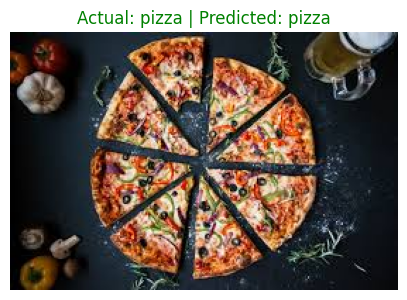

In [138]:
plot_prediction_image(model_1,
                      str(custom_image_path),
                      device)